### Exercise 2

Using SVM, classify emails as spam or not spam based on word frequency and message length. Using the UCI Spambase dataset here, features are word/char frequencies plus the capital_run_length columns which act as a stand-in for message length/formatting.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from sklearn import metrics
import seaborn as sn

In [2]:
col_names = ['word_freq_make', 'word_freq_address', 'word_freq_all', 'word_freq_3d', 'word_freq_our',
'word_freq_over', 'word_freq_remove', 'word_freq_internet', 'word_freq_order', 'word_freq_mail',
'word_freq_receive', 'word_freq_will', 'word_freq_people', 'word_freq_report', 'word_freq_addresses',
'word_freq_free', 'word_freq_business', 'word_freq_email', 'word_freq_you', 'word_freq_credit',
'word_freq_your', 'word_freq_font', 'word_freq_000', 'word_freq_money', 'word_freq_hp',
'word_freq_hpl', 'word_freq_george', 'word_freq_650', 'word_freq_lab', 'word_freq_labs',
'word_freq_telnet', 'word_freq_857', 'word_freq_data', 'word_freq_415', 'word_freq_85',
'word_freq_technology', 'word_freq_1999', 'word_freq_parts', 'word_freq_pm', 'word_freq_direct',
'word_freq_cs', 'word_freq_meeting', 'word_freq_original', 'word_freq_project', 'word_freq_re',
'word_freq_edu', 'word_freq_table', 'word_freq_conference', 'char_freq_semicolon', 'char_freq_paren',
'char_freq_bracket', 'char_freq_excl', 'char_freq_dollar', 'char_freq_hash',
'capital_run_length_average', 'capital_run_length_longest', 'capital_run_length_total', 'spam']

data = pd.read_csv('spambase.data', header=None, names=col_names)

print(data.shape)
data.head()

(4601, 58)


,word_freq_make,word_freq_address,word_freq_all,word_freq_3d,word_freq_our,word_freq_over,word_freq_remove,word_freq_internet,word_freq_order,word_freq_mail,...,char_freq_semicolon,char_freq_paren,char_freq_bracket,char_freq_excl,char_freq_dollar,char_freq_hash,capital_run_length_average,capital_run_length_longest,capital_run_length_total,spam
0,0.00,0.64,0.64,0.0,0.32,0.00,0.00,0.00,0.00,0.00,...,0.00,0.000,0.0,0.778,0.000,0.000,3.756,61,278,1
1,0.21,0.28,0.50,0.0,0.14,0.28,0.21,0.07,0.00,0.94,...,0.00,0.132,0.0,0.372,0.180,0.048,5.114,101,1028,1
2,0.06,0.00,0.71,0.0,1.23,0.19,0.19,0.12,0.64,0.25,...,0.01,0.143,0.0,0.276,0.184,0.010,9.821,485,2259,1
3,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.137,0.0,0.137,0.000,0.000,3.537,40,191,1
4,0.00,0.00,0.00,0.0,0.63,0.00,0.31,0.63,0.31,0.63,...,0.00,0.135,0.0,0.135,0.000,0.000,3.537,40,191,1


In [3]:
data.isnull().sum().sum()

np.int64(0)

In [4]:
x = data.drop('spam', axis=1)
y = data['spam']

In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=5)

print(x_train.shape, y_train.shape, x_test.shape, y_test.shape)

(3220, 57) (3220,) (1381, 57) (1381,)


In [6]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

In [7]:
model = SVC(kernel='rbf', random_state=0)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

SVC [kernel - rbf]
[[816  36]
 [ 60 469]]
Accuracy: 0.9304851556842868
Accuracy in Percentage: 93 %
              precision    recall  f1-score   support

           0       0.96      0.93      0.94       876
           1       0.89      0.93      0.91       505

    accuracy                           0.93      1381
   macro avg       0.92      0.93      0.93      1381
weighted avg       0.93      0.93      0.93      1381



[Text(0.5, 1.0, 'SVC [rbf] - spam')]

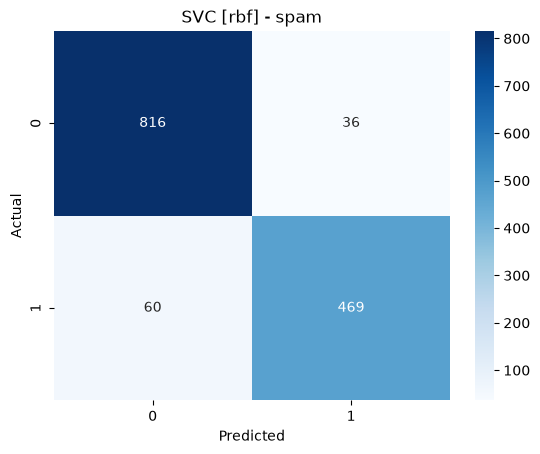

In [8]:
conf_matrix = metrics.confusion_matrix(y_test, y_pred)
print('SVC [kernel - rbf]')
print(conf_matrix)

accuracy_score = metrics.accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy_score)
print("Accuracy in Percentage:", int(accuracy_score*100), "%")
print(classification_report(y_pred, y_test))

conf_mat = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
sn.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues').set(title='SVC [rbf] - spam')